# 11. E2 Tambahan: Level Bloom pada Soal Berlabel

Dataset publik berlabel Bloom yang bisa diunduh semuanya melabeli **soal**, bukan jawaban mahasiswa. Jadi notebook ini menguji hal yang lebih sempit: apakah kamus kata kerja heuristik dan Groq mengenali level Bloom yang dituntut sebuah soal.

| Dataset | Isi | Lisensi |
|---|---|---|
| prawiraadam/finalproject | 681 soal SD-SMA bahasa Indonesia, label C1-C6 | tidak dicantumkan, jadi hanya diunduh lokal |
| Yahya dkk. (2012) | 600 soal bahasa Inggris, 100 per level | MIT (repo pengumpul) |

Yang boleh diklaim: kamus dan LLM mengenali taksonomi Bloom pada soal. Yang tidak boleh diklaim: akurasi level Bloom pada jawaban mahasiswa.

Kamus kata kerja heuristik mengikuti proses kognitif Krathwohl (2002): membandingkan dan mengklasifikasikan masuk Memahami, memeriksa masuk Mengevaluasi.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
import requests

from src import notebook_kit as kit
from src.evaluate_baseline import bootstrap_backend

pd.set_option("display.max_colwidth", 90)

KEYS = kit.use_keys(groq_env="GROQ_API_KEY_BLOOM")
bootstrap_backend()
from apps.analysis.engines.bloom import BLOOM_LABELS, estimate_bloom_level
from apps.analysis.engines.text_features import BLOOM_VERBS, extract_features

DATA_DIR = ROOT / "data" / "bloom_soal"
CACHE = ROOT / "data" / "cache" / "e2_bloom_soal.jsonl"
OUT = kit.results_dir("e2_bloom_soal")
DATA_DIR.mkdir(parents=True, exist_ok=True)

SOURCES = {
    "indonesia": "https://raw.githubusercontent.com/prawiraadam/finalproject/HEAD/data/data_test.csv",
    "yahya": "https://gitlab.com/zrasoulkhani/bloom-classification-aied2026/-/raw/main/data/yahya-2012_revised.csv",
}
PER_LEVEL = 40
BATCH = 10
SEED = 42
MODEL = "openai/gpt-oss-120b"
ENGLISH_LEVELS = {"Remember": 1, "Understand": 2, "Apply": 3, "Analyze": 4, "Evaluate": 5, "Create": 6}

Kunci: groq ada, winston ada


## 1. Data

Kedua berkas diunduh sekali ke `data/bloom_soal/`. Dari tiap level diambil paling banyak 40 soal secara acak supaya level yang banyak tidak mendominasi.

In [2]:
for name, url in SOURCES.items():
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)

indo = pd.read_csv(DATA_DIR / "indonesia.csv", sep=";", encoding="utf-8-sig")
indo = pd.DataFrame({"dataset": "indonesia", "question": indo.question.astype(str).str.strip(),
                     "level": indo.label.str[1].astype(int)})
yahya = pd.read_csv(DATA_DIR / "yahya.csv")
yahya = pd.DataFrame({"dataset": "yahya", "question": yahya.QUESTION.astype(str).str.strip(),
                      "level": yahya["BT LEVEL"].str.strip().map(ENGLISH_LEVELS)})

full = pd.concat([indo, yahya], ignore_index=True).dropna().drop_duplicates("question")
sample = (full.sample(frac=1, random_state=SEED).groupby(["dataset", "level"]).head(PER_LEVEL)
          .sort_values(["dataset", "level"]).reset_index(drop=True))
sample["level"] = sample.level.astype(int)
pd.crosstab(sample.dataset, sample.level, margins=True)

level,1,2,3,4,5,6,All
dataset,,,,,,,
indonesia,40,40,40,40,37,19,216
yahya,40,40,40,40,40,40,240
All,80,80,80,80,77,59,456


## 2. Heuristik

Penaksir level produksi (`estimate_bloom_level`) dirancang untuk jawaban panjang. Soal rata-rata hanya belasan kata, sehingga batas panjang menguncinya di L1. Karena itu yang diuji adalah kamus kata kerjanya saja.

Soal memakai bentuk perintah ("Jelaskan", "Sebutkan"), sedangkan kamus memakai bentuk meN- ("menjelaskan", "menyebutkan"). Setiap kata kerja kamus diubah ke bentuk perintahnya, lalu level tertinggi yang ditemukan dipakai sebagai tebakan. Kamus hanya bisa dinilai pada soal bahasa Indonesia.

In [3]:
indo_sample = sample[sample.dataset == "indonesia"].copy()
production = indo_sample.question.map(lambda q: estimate_bloom_level(extract_features(q)).level)
print(f"Penaksir produksi pada soal: {production.eq(1).mean():.0%} soal jatuh ke L1")


def imperative_forms(verb):
    forms = {verb}
    for prefix, restore in (("meny", "s"), ("meng", "k"), ("mem", "p"), ("men", "t"), ("me", "")):
        if verb.startswith(prefix):
            rest = verb[len(prefix):]
            forms |= {rest, restore + rest}
            break
    return forms


def lexicon_level(question, verbs):
    text = question.lower()
    words = {w.removesuffix("lah") for w in re.findall(r"\w+", text)}
    hits = [level for level, items in verbs.items() for verb in items
            if (" " in verb and verb in text) or words & imperative_forms(verb)]
    return max(hits) if hits else None


OLD_VERBS = {level: tuple(v for v in verbs if v not in ("membandingkan", "mengklasifikasikan", "memeriksa"))
             for level, verbs in BLOOM_VERBS.items()}
OLD_VERBS[4] += ("membandingkan", "mengklasifikasikan", "memeriksa")

rows = []
for name, verbs in (("kamus lama", OLD_VERBS), ("kamus Krathwohl", BLOOM_VERBS)):
    pred = indo_sample.question.map(lambda q: lexicon_level(q, verbs))
    hit = pred.notna()
    rows.append({"kamus": name, "soal": len(pred), "ada kata kerja": f"{hit.mean():.0%}",
                 "tepat (dari yang ada)": round((pred[hit] == indo_sample.level[hit]).mean(), 3),
                 "selisih ≤1": round(((pred[hit] - indo_sample.level[hit]).abs() <= 1).mean(), 3)})
    indo_sample[name] = pred
lexicon = pd.DataFrame(rows)
lexicon

Penaksir produksi pada soal: 100% soal jatuh ke L1


,kamus,soal,ada kata kerja,tepat (dari yang ada),selisih ≤1
0,kamus lama,216,10%,0.19,0.333
1,kamus Krathwohl,216,10%,0.19,0.333


## 3. Groq

Groq diberi prompt pendek: level Bloom yang dituntut tiap soal. Soal dikirim 10 sekaligus supaya hemat kuota. Hasil disimpan di cache.

In [4]:
PROMPT = """Untuk tiap soal di bawah, tentukan level Taksonomi Bloom revisi (Anderson & Krathwohl) yang DITUNTUT soal itu:
1 Mengingat, 2 Memahami, 3 Menerapkan, 4 Menganalisis, 5 Mengevaluasi, 6 Mencipta.
Jawab hanya JSON: {{"levels": [angka untuk soal 1, soal 2, ...]}} dengan {n} angka.

{questions}"""

cache = kit.load_jsonl(CACHE)


def ask(batch):
    key = "bloom_soal:" + hashlib.sha256("\n".join(batch).encode()).hexdigest()[:16]
    if key not in cache:
        numbered = "\n".join(f"{i}. {q}" for i, q in enumerate(batch, start=1))
        text = kit.with_retry(kit.groq_chat, PROMPT.format(n=len(batch), questions=numbered), MODEL,
                              temperature=0.0, max_tokens=1500)
        levels = json.loads(re.search(r"\{.*\}", text, re.S).group(0))["levels"]
        if len(levels) != len(batch):
            raise ValueError(f"Groq mengembalikan {len(levels)} level untuk {len(batch)} soal")
        cache[key] = {"levels": [int(x) for x in levels]}
        kit.append_jsonl(CACHE, key, cache[key])
    return cache[key]["levels"]


if KEYS["groq"]:
    for dataset, part in sample.groupby("dataset"):
        for start in range(0, len(part), BATCH):
            chunk = part.iloc[start:start + BATCH]
            sample.loc[chunk.index, "groq"] = ask(chunk.question.tolist())
    sample["groq"] = sample.groq.astype("Int64")
print(f"{sample.groq.notna().sum()} soal dinilai Groq")

456 soal dinilai Groq


## 4. Hasil

Tepat = level sama persis. Selisih ≤1 = meleset paling jauh satu level. Kappa kuadrat menghukum kesalahan jauh lebih berat daripada kesalahan dekat.

In [5]:
def score(part, column):
    ok = part[column].notna()
    pred, truth = part.loc[ok, column].astype(int), part.loc[ok, "level"]
    return pd.Series({
        "n": int(ok.sum()),
        "tepat": round((pred == truth).mean(), 3),
        "selisih ≤1": round(((pred - truth).abs() <= 1).mean(), 3),
        "kappa kuadrat": round(kit.quadratic_kappa(truth.tolist(), pred.tolist()), 3),
    })


summary = pd.DataFrame({
    "Groq, soal Indonesia": score(sample[sample.dataset == "indonesia"], "groq"),
    "Groq, soal Yahya (Inggris)": score(sample[sample.dataset == "yahya"], "groq"),
    "Kamus Krathwohl, soal Indonesia": score(indo_sample, "kamus Krathwohl"),
}).T
per_level = sample.assign(benar=sample.groq == sample.level).pivot_table(
    index="level", columns="dataset", values="benar", aggfunc="mean").round(2)
per_level.index = [f"L{i} {BLOOM_LABELS[i]}" for i in per_level.index]
display(summary)
per_level

,n,tepat,selisih ≤1,kappa kuadrat
"Groq, soal Indonesia",216.0,0.352,0.676,0.387
"Groq, soal Yahya (Inggris)",240.0,0.571,0.775,0.682
"Kamus Krathwohl, soal Indonesia",21.0,0.190,0.333,-0.000


dataset,indonesia,yahya
L1 Mengingat,0.65,0.72
L2 Memahami,0.2,0.52
L3 Menerapkan,0.65,0.32
L4 Menganalisis,0.15,0.55
L5 Mengevaluasi,0.16,0.57
L6 Mencipta,0.21,0.72


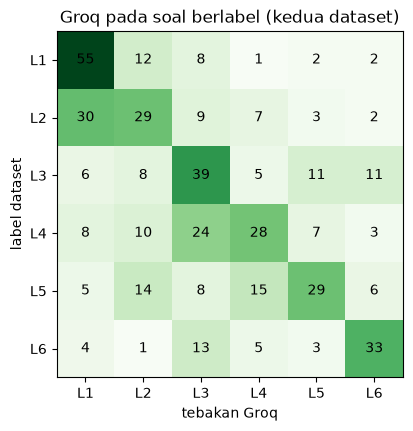

In [6]:
confusion = pd.crosstab(sample.level, sample.groq).reindex(index=range(1, 7), columns=range(1, 7), fill_value=0)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(confusion, cmap="Greens")
for i in range(6):
    for j in range(6):
        ax.text(j, i, confusion.iat[i, j], ha="center", va="center")
ax.set_xticks(range(6), [f"L{i}" for i in range(1, 7)])
ax.set_yticks(range(6), [f"L{i}" for i in range(1, 7)])
ax.set_xlabel("tebakan Groq")
ax.set_ylabel("label dataset")
ax.set_title("Groq pada soal berlabel (kedua dataset)")
kit.save_figure(fig, "e2_bloom_soal_groq.png")
plt.show()

## 5. Kesimpulan

Ringkasan disimpan ke `results/e2_bloom_soal/`. Teks soal tidak ikut disimpan.

In [7]:
summary.to_csv(OUT / "ringkasan_penilai.csv")
lexicon.to_csv(OUT / "kamus_kata_kerja.csv", index=False)
sample[["dataset", "level", "groq"]].join(indo_sample[["kamus Krathwohl"]]).to_csv(OUT / "per_soal.csv", index=False)

kit.write_summary(OUT / "ringkasan.md", "E2 tambahan: level Bloom pada soal berlabel", {
    "Data": f"{(sample.dataset == 'indonesia').sum()} soal Indonesia (prawiraadam/finalproject) dan "
            f"{(sample.dataset == 'yahya').sum()} soal Inggris (Yahya dkk. 2012), maksimal {PER_LEVEL} per level.",
    "Penilai": kit.md_table(summary.reset_index(names="penilai")),
    "Ketepatan Groq per level": kit.md_table(per_level.reset_index(names="level")),
    "Kamus kata kerja heuristik": kit.md_table(lexicon) + "\n\n"
        f"Penaksir produksi pada soal: {production.eq(1).mean():.0%} soal jatuh ke L1 karena batas panjang.",
    "Batasan": "- Label dataset melekat pada soal, bukan pada jawaban mahasiswa.\n"
               "- Pelabel dan kesepakatan antar-pelabel dataset Indonesia tidak dilaporkan.\n"
               "- Groq di sini memakai prompt pendek khusus soal, bukan prompt produksi.\n"
               "- Soal pilihan ganda dinilai dari kalimat soalnya saja, tanpa teks bacaan.\n"
               "- Kamus kata kerja Krathwohl (2002); penaksir produksi tidak diuji karena dirancang untuk teks panjang.",
})
print((OUT / "ringkasan.md").read_text())

# E2 tambahan: level Bloom pada soal berlabel

## Data

216 soal Indonesia (prawiraadam/finalproject) dan 240 soal Inggris (Yahya dkk. 2012), maksimal 40 per level.

## Penilai

| penilai | n | tepat | selisih ≤1 | kappa kuadrat |
|---|---|---|---|---|
| Groq, soal Indonesia | 216.0 | 0.352 | 0.676 | 0.387 |
| Groq, soal Yahya (Inggris) | 240.0 | 0.571 | 0.775 | 0.682 |
| Kamus Krathwohl, soal Indonesia | 21.0 | 0.19 | 0.333 | -0.0 |

## Ketepatan Groq per level

| level | indonesia | yahya |
|---|---|---|
| L1 Mengingat | 0.65 | 0.72 |
| L2 Memahami | 0.2 | 0.52 |
| L3 Menerapkan | 0.65 | 0.32 |
| L4 Menganalisis | 0.15 | 0.55 |
| L5 Mengevaluasi | 0.16 | 0.57 |
| L6 Mencipta | 0.21 | 0.72 |

## Kamus kata kerja heuristik

| kamus | soal | ada kata kerja | tepat (dari yang ada) | selisih ≤1 |
|---|---|---|---|---|
| kamus lama | 216 | 10% | 0.19 | 0.333 |
| kamus Krathwohl | 216 | 10% | 0.19 | 0.333 |

Penaksir produksi pada soal: 100% soal jatuh ke L1 karena batas panjang.

## Batasa